# Chapitre 10 - Cours 1 : traitement par lots avec les outils Unix

Les chapitres précédents parlaient de requêtes et de réponses : un client demande, le
système répond le plus vite possible. Le traitement **par lots** (*batch processing*)
change de point de vue : un job lit un gros volume de données d'entrée, calcule pendant
des minutes ou des heures, et écrit une sortie entièrement **dérivée** de son entrée. Ce
premier cours en pose l'intuition sur une seule machine, avec le plus ancien des
frameworks de traitement par lots : le shell Unix. Il couvre l'introduction du chapitre et
la section *Batch Processing with Unix Tools* (*Simple Log Analysis*, *Chain of commands versus custom program*, *Sorting versus in-memory aggregation*, *The Unix Philosophy*).

**Plan.**

1. Trois façons de traiter des données : en ligne, par lots, en flux.
2. Une analyse de journal avec `awk`, `sort`, `uniq` et `head`.
3. Chaîne de commandes contre programme : même résultat, exécution différente.
4. Trier ou agréger en mémoire : l'ensemble de travail et le tri externe.
5. Les tuyaux, un tampon borné et la contre-pression.
6. La philosophie Unix : interface uniforme, logique séparée du câblage, expérimentation.

**Contexte : la troisième partie du livre.** Ce chapitre ouvre la partie III, *Derived
Data*. Son introduction distingue deux familles de systèmes de données. Un **système de
référence** (*system of record*, la « source de vérité ») détient la version faisant foi
de chaque donnée : quand une information y entre, elle y est écrite une fois, et en cas
de désaccord c'est lui qui a raison. Un système de **données dérivées** contient le
résultat d'une transformation de données venues d'ailleurs : cache, index, vue
matérialisée, modèle de recommandation. Une donnée dérivée est redondante (on pourrait
la recalculer depuis la source) mais elle rend les lectures rapides. Le traitement par
lots est l'outil type pour construire de telles données dérivées.

In [1]:
import os
import shutil
import subprocess
import tempfile
import time
import tracemalloc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
WORK = tempfile.mkdtemp(prefix="ddia_ch10_")      # dossier de travail, effacé en fin de notebook
ENV_C = dict(os.environ, LC_ALL="C")                  # tri octet par octet : rapide et déterministe


def sh(cmd):
    """Lance une commande shell et renvoie sa sortie standard."""
    return subprocess.run(cmd, shell=True, check=True, capture_output=True, text=True, env=ENV_C).stdout

## 1. Trois façons de traiter des données (introduction du chapitre)

Le livre oppose trois styles de systèmes (l'introduction du chapitre les présente comme *services*, *batch processing systems* et *stream processing systems*) :

- les systèmes **en ligne** (*online*) : un service web, une base de données, un cache,
  un index de recherche. Ils attendent une requête et répondent vite ; leur mesure de
  performance est le **temps de réponse**, et ils doivent rester disponibles ;
- les systèmes **par lots** (*offline*) : un job prend une grande quantité de données
  d'entrée **en lecture seule**, la traite et produit une sortie **regénérée de zéro** à
  chaque exécution. Personne n'attend devant l'écran ; la mesure de performance est le
  **débit** (combien de données par unité de temps). Un job tourne souvent
  périodiquement, par exemple chaque nuit ;
- les systèmes **en flux** (*stream processing*, chapitre 11) : entre les deux,
  le job ne se termine jamais, il consomme les nouvelles entrées peu après leur arrivée.

Le schéma ci-dessous place un job de lots dans un système : il lit une copie immuable des
données de référence et écrit des données dérivées que les services en ligne consultent.

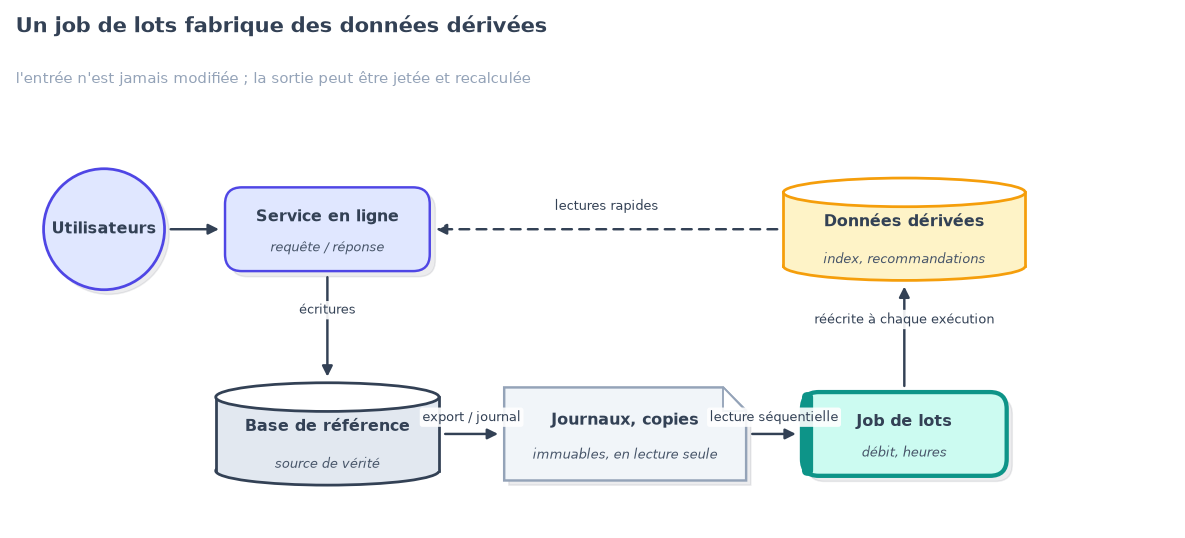

In [2]:
d = Diagram(12.5, 4.6, title="Un job de lots fabrique des données dérivées",
            subtitle="l'entrée n'est jamais modifiée ; la sortie peut être jetée et recalculée")
d.box("u", 1.0, 3.2, "Utilisateurs", kind="user", w=1.3, color=INDIGO)
d.box("app", 3.4, 3.2, "Service en ligne", sub="requête / réponse", color=INDIGO)
d.box("db", 3.4, 1.0, "Base de référence", sub="source de vérité", color=SLATE, kind="db", w=2.4, h=1.1)
d.box("logs", 6.6, 1.0, "Journaux, copies", sub="immuables, en lecture seule", color=GRAY, kind="doc", w=2.6, h=1.0)
d.box("job", 9.6, 1.0, "Job de lots", sub="débit, heures", color=TEAL, kind="model", w=2.2)
d.box("out", 9.6, 3.2, "Données dérivées", sub="index, recommandations", color=AMBER, kind="db", w=2.6, h=1.1)
d.arrow("u", "app", "")
d.arrow("app", "db", "écritures")
d.arrow("db", "logs", "export / journal")
d.arrow("logs", "job", "lecture séquentielle")
d.arrow("job", "out", "réécrite à chaque exécution")
d.arrow("out", "app", "lectures rapides", style="dashed", label_offset=(0, 0.25))
d.show()

**Pourquoi une entrée immuable change tout.** Si un job a un bogue, sa sortie est fausse,
mais l'entrée est intacte : on corrige le code et on relance, ou plus simplement on
rebascule sur la sortie de la veille, gardée dans un autre répertoire. Une base de
données modifiée en place par un code bogué, elle, garde les dégâts même après retour à
l'ancien code. Le livre parle de **tolérance aux fautes humaines** (*human fault
tolerance*). Le cours 5 y reviendra avec une démonstration.

Les ordres de grandeur ci-dessous (illustratifs) montrent ce qui sépare les trois mondes
: on n'optimise pas la même chose quand une réponse doit arriver en 10 ms et quand un job
a la nuit pour lire des téraoctets.

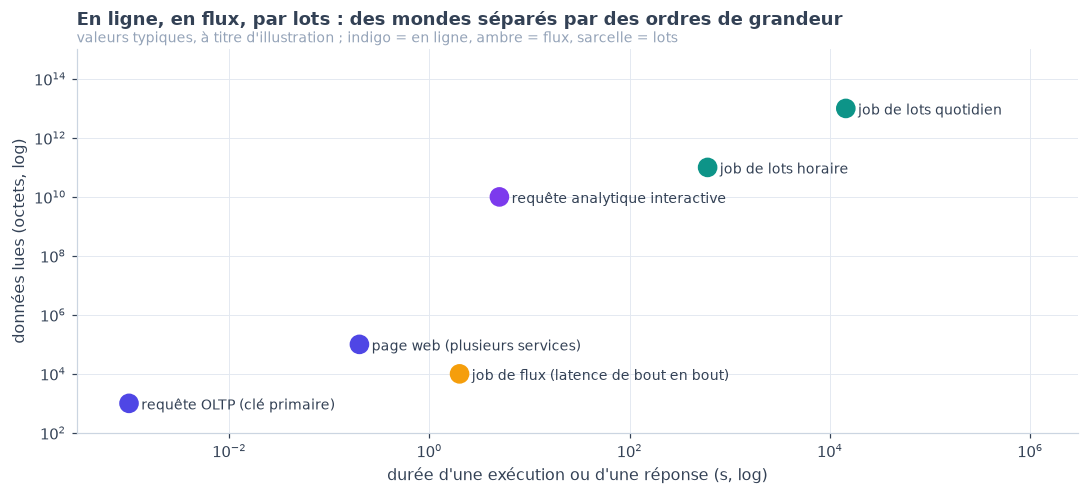

In [3]:
systemes = pd.DataFrame([
    ("requête OLTP (clé primaire)", 1e-3, 1e3, INDIGO),
    ("page web (plusieurs services)", 0.2, 1e5, INDIGO),
    ("requête analytique interactive", 5, 1e10, VIOLET),
    ("job de flux (latence de bout en bout)", 2, 1e4, AMBER),
    ("job de lots horaire", 600, 1e11, TEAL),
    ("job de lots quotidien", 4 * 3600, 1e13, TEAL),
], columns=["systeme", "duree_s", "octets", "couleur"])
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.scatter(systemes.duree_s, systemes.octets, s=140, c=systemes.couleur, zorder=3)
for _, r in systemes.iterrows():
    ax.annotate(r.systeme, (r.duree_s, r.octets), (8, -4), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(3e-4, 3e6); ax.set_ylim(1e2, 1e15)
ax.set_xlabel("durée d'une exécution ou d'une réponse (s, log)")
ax.set_ylabel("données lues (octets, log)")
ax.set_title("En ligne, en flux, par lots : des mondes séparés par des ordres de grandeur")
subtitle(ax, "valeurs typiques, à titre d'illustration ; indigo = en ligne, ambre = flux, sarcelle = lots")
plt.tight_layout(); plt.show()

> **À retenir.** Un job de lots lit une entrée **immuable** et produit une sortie
> **dérivée**, recalculée de zéro. On le juge à son débit, pas à son temps de réponse.
> Cette discipline permet de corriger une erreur en relançant le job, ce qu'une base
> modifiée en place ne permet pas.

## 2. Une analyse de journal avec les outils Unix (section *Simple Log Analysis*)

Un serveur web ajoute une ligne à son journal d'accès à chaque requête servie. Au format
« combined » de NGINX, une ligne contient l'adresse IP du client, l'utilisateur
authentifié (ou `-`), la date, la ligne de requête HTTP, le code de statut, la taille de
la réponse, la page d'origine (*referer*) et le navigateur (*user agent*). Faute de vrais
journaux, `B.generate_access_log` en fabrique : 400 000 requêtes sur 3 000 URL dont la
popularité suit une loi de Zipf (quelques pages très demandées, une longue traîne), comme
sur un vrai site.

In [4]:
lines = B.generate_access_log(400_000, n_urls=3000, s=1.1, seed=1)
LOG = os.path.join(WORK, "access.log")
taille = B.write_lines(LOG, lines)
print(f"{len(lines):,} lignes, {taille / 1e6:.0f} Mo".replace(",", " "))
print(lines[12])
champs = lines[12].split()
pd.DataFrame({"champ pour awk": [f"${i + 1}" for i in range(10)], "valeur": champs[:10]}).set_index("champ pour awk")

400 000 lignes  92 Mo
114.239.140.149 - - [15/Nov/2022:00:00:03 +0000] "GET /2022/05/15/schema-paxos-streams-curves.html HTTP/1.1" 200 32146 "https://example.org/" "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:106.0) Gecko/20100101 Firefox/106.0"


,valeur
champ pour awk,
$1,114.239.140.149
$2,-
$3,-
$4,[15/Nov/2022:00:00:03
$5,+0000]
$6,"""GET"
$7,/2022/05/15/schema-paxos-streams-curves.html
$8,"HTTP/1.1"""
$9,200


Le septième champ séparé par des espaces (`$7` pour `awk`) est l'URL. Les cinq pages les
plus vues s'obtiennent par le pipeline que le livre présente :

```
cat access.log | awk '{print $7}' | sort | uniq -c | sort -r -n | head -n 5
```

`awk` extrait l'URL de chaque ligne ; `sort` range les URL par ordre alphabétique, ce qui
met côte à côte toutes les occurrences d'une même URL ; `uniq -c` remplace chaque série
de lignes identiques **adjacentes** par une seule ligne précédée de son nombre ; le second
`sort -r -n` classe par nombre décroissant, et `head` garde les cinq premières. Lançons
les vrais outils, puis regardons ce qui circule dans chaque tuyau.

In [5]:
top_unix, duree_unix = B.unix_top_k(LOG, 5)
print(f"pipeline Unix : {duree_unix:.2f} s")
for c, u in top_unix:
    print(f"{c:>7} {u}")

pipeline Unix : 0.13 s
  65714 /
  30692 /favicon.ico
  19648 /2014/10/19/shuffle-collaboration-streams.html
  14418 /2014/06/28/ethics-locking-streams.html
  11273 /2022/05/15/schema-paxos-streams-curves.html


In [6]:
etapes = {
    "awk '{print $7}'": f"awk '{{print $7}}' {LOG}",
    "| sort": f"awk '{{print $7}}' {LOG} | sort",
    "| uniq -c": f"awk '{{print $7}}' {LOG} | sort | uniq -c",
    "| sort -r -n": f"awk '{{print $7}}' {LOG} | sort | uniq -c | sort -r -n",
}
rows = []
for nom, cmd in etapes.items():
    out = sh(cmd).splitlines()
    rows.append({"étape": nom, "lignes en sortie": len(out), "3 premières lignes": " | ".join(x.strip() for x in out[:3])})
pd.DataFrame(rows)

,étape,lignes en sortie,3 premières lignes
0,awk '{print $7}',400000,/2021/12/04/first-crdt.html | /2017/12/11/logs-lsm-shuffle-schema.html | /
1,| sort,400000,/ | / | /
2,| uniq -c,3000,65714 / | 24 /2010/01/01/automerge-ethics-local-collaboration.html | 14 /2010/01/01/lo...
3,| sort -r -n,3000,65714 / | 30692 /favicon.ico | 19648 /2014/10/19/shuffle-collaboration-streams.html


Le tableau montre le rôle du tri : après `sort`, les 400 000 URL sont toujours là, mais
regroupées ; `uniq -c` les réduit à une ligne par URL distincte (moins de 3 000) ; seul ce
petit résultat est trié une seconde fois. La figure suivante montre la distribution
obtenue : les dix pages les plus vues totalisent une grosse part du trafic.

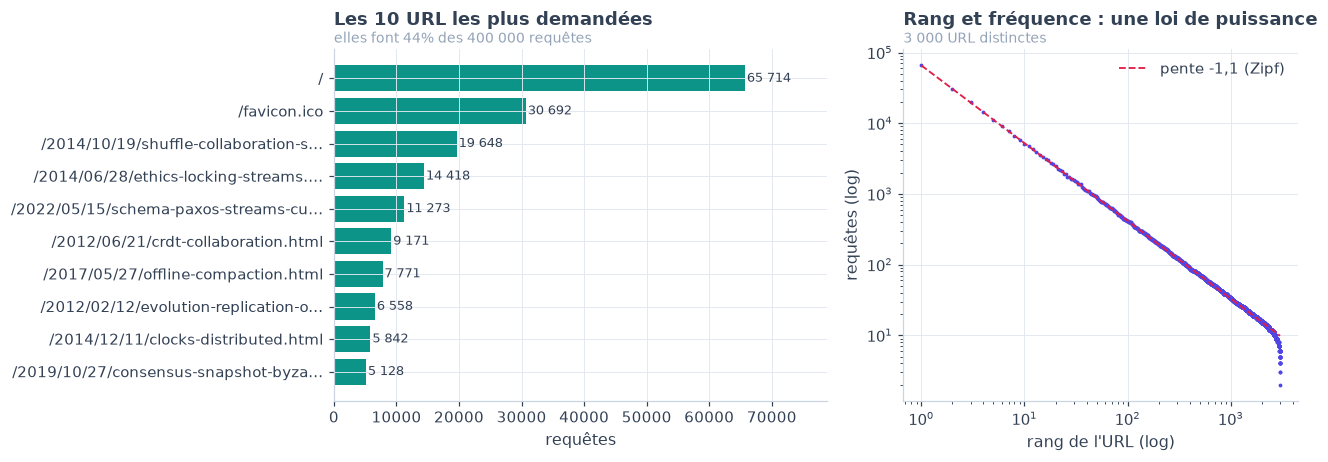

In [7]:
counts = pd.Series([B.url_of(l) for l in lines]).value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
top = counts.head(10)[::-1]
axes[0].barh([u if len(u) < 38 else u[:35] + "..." for u in top.index], top.values, color=TEAL)
for i, v in enumerate(top.values):
    axes[0].text(v + 300, i, f"{v:,}".replace(",", " "), va="center", fontsize=8.5)
axes[0].set_xlabel("requêtes"); axes[0].set_xlim(0, top.max() * 1.2)
axes[0].set_title("Les 10 URL les plus demandées")
part10 = counts.head(10).sum() / counts.sum()
subtitle(axes[0], f"elles font {part10:.0%} des {counts.sum():,} requêtes".replace(",", " "))
rang = np.arange(1, len(counts) + 1)
axes[1].loglog(rang, counts.values, ".", color=INDIGO, ms=3)
axes[1].loglog(rang, counts.values[0] * rang ** -1.1, color=ROSE, lw=1.2, ls="--", label="pente -1,1 (Zipf)")
axes[1].set_xlabel("rang de l'URL (log)"); axes[1].set_ylabel("requêtes (log)")
axes[1].set_title("Rang et fréquence : une loi de puissance")
subtitle(axes[1], f"{len(counts):,} URL distinctes".replace(",", " "))
axes[1].legend()
plt.tight_layout(); plt.show()

**Modifier l'analyse coûte une ligne.** Pour ignorer les feuilles de style, on change le
programme `awk` en `$7 !~ /\.css$/ {print $7}` ; pour classer les adresses IP au lieu des
pages, on extrait `$1`. Le reste du pipeline ne change pas.

In [8]:
variantes = {
    "pages hors CSS": r"$7 !~ /\.css$/ {print $7}",
    "adresses IP": "{print $1}",
    "codes de statut": "{print $9}",
}
res = {}
for nom, prog in variantes.items():
    top3, dt = B.unix_top_k(LOG, 3, awk_prog=prog)
    res[nom] = [f"{c} {u}" for c, u in top3] + [f"{dt:.2f} s"]
pd.DataFrame(res, index=["1er", "2e", "3e", "durée"])

,pages hors CSS,adresses IP,codes de statut
1er,65714 /,28579 143.155.140.49,299521 200
2e,30692 /favicon.ico,15364 16.12.244.120,50418 304
3e,19648 /2014/10/19/shuffle-collaboration-streams.html,10721 14.105.120.10,50061 404
durée,0.13 s,0.12 s,0.11 s


> **À retenir.** Un pipeline `awk | sort | uniq -c | sort -rn | head` répond à une
> question analytique sur des centaines de mégaoctets en moins d'une seconde. Le **tri**
> y joue le rôle central : il rend adjacentes les lignes de même clé, si bien que
> compter devient un simple parcours séquentiel.

## 3. Chaîne de commandes contre programme (section *Chain of commands versus custom program*)

Le même calcul s'écrit en quelques lignes de Python : une table de hachage associe à
chaque URL un compteur, puis on trie les couples (compte, URL). Le résultat est
identique ; la différence, que le livre souligne, est dans le **déroulement** : le script
garde une table en mémoire et ne trie que les URL distinctes, le pipeline trie toutes
les lignes et ne garde presque rien en mémoire. Chaque commande du pipeline est un
**processus** distinct ; le noyau les relie par des tuyaux (*pipes*) et les exécute en
parallèle sur plusieurs cœurs.

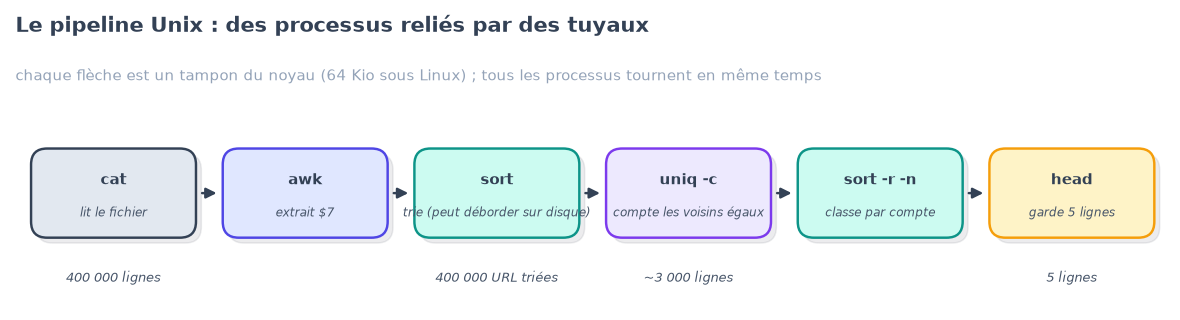

In [9]:
d = Diagram(13, 2.4, title="Le pipeline Unix : des processus reliés par des tuyaux",
            subtitle="chaque flèche est un tampon du noyau (64 Kio sous Linux) ; tous les processus tournent en même temps")
noms = [("cat", "cat", "lit le fichier"), ("awk", "awk", "extrait $7"), ("sort1", "sort", "trie (peut déborder sur disque)"),
        ("uniq", "uniq -c", "compte les voisins égaux"), ("sort2", "sort -r -n", "classe par compte"), ("head", "head", "garde 5 lignes")]
d.flow(noms, y=1.3, x0=1.15, dx=2.15, w=1.85, h=1.0, fontsize=10,
       colors=[SLATE, INDIGO, TEAL, VIOLET, TEAL, AMBER], labels=["", "", "", "", ""])
d.note(1.15, 0.35, "400 000 lignes", fontsize=8.5)
d.note(5.45, 0.35, "400 000 URL triées", fontsize=8.5)
d.note(7.6, 0.35, "~3 000 lignes", fontsize=8.5)
d.note(11.9, 0.35, "5 lignes", fontsize=8.5)
d.show()

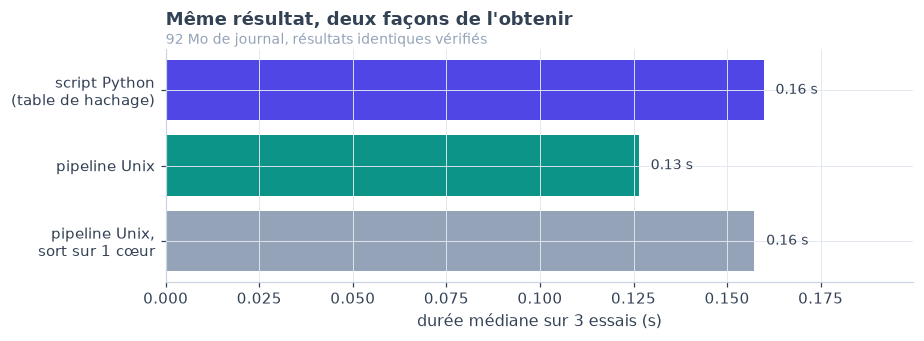

In [10]:
def top5_python(path):
    from collections import defaultdict
    counts = defaultdict(int)
    with open(path) as f:
        for line in f:
            counts[line.split()[6]] += 1
    return sorted(((c, u) for u, c in counts.items()), reverse=True)[:5]


mesures = []
for essai in range(3):
    t0 = time.perf_counter(); top_py = top5_python(LOG); t_py = time.perf_counter() - t0
    _, t_unix = B.unix_top_k(LOG, 5)
    _, t_unix1 = B.unix_top_k(LOG, 5, sort_opts="--parallel=1")
    mesures.append((t_py, t_unix, t_unix1))
m = np.median(np.array(mesures), axis=0)
assert top_py == top_unix
fig, ax = plt.subplots(figsize=(8.5, 3.2))
labels = ["script Python\n(table de hachage)", "pipeline Unix", "pipeline Unix,\nsort sur 1 cœur"]
ax.barh(labels, m, color=[INDIGO, TEAL, GRAY])
for i, v in enumerate(m):
    ax.text(v + m.max() * 0.02, i, f"{v:.2f} s", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, m.max() * 1.25)
ax.set_xlabel("durée médiane sur 3 essais (s)")
ax.set_title("Même résultat, deux façons de l'obtenir")
subtitle(ax, f"{taille / 1e6:.0f} Mo de journal, résultats identiques vérifiés")
plt.tight_layout(); plt.show()

Sur ce fichier de taille modeste, les deux approches sont du même ordre de grandeur (le
détail dépend de la machine) : Python paie l'interprétation ligne à ligne, le pipeline
paie le tri de toutes les lignes mais répartit le travail entre plusieurs processus.
La vraie différence n'apparaît que lorsque les données ne tiennent plus en mémoire :
c'est l'objet de la section suivante.

> **À retenir.** Un script à table de hachage et un pipeline fondé sur le tri calculent
> la même chose ; le premier garde en mémoire une entrée par clé distincte, le second
> trie tout mais en flux, avec plusieurs processus qui travaillent en parallèle.

## 4. Trier ou agréger en mémoire (section *Sorting versus in-memory aggregation*)

**L'ensemble de travail.** La mémoire dont le script a besoin en accès aléatoire (son
*working set*) dépend seulement du nombre d'URL **distinctes**, pas du nombre de lignes :
un million de requêtes vers la même page ne coûtent qu'une entrée. Mesurons la mémoire
réelle d'un dictionnaire Python de compteurs (avec `tracemalloc`) en fonction du nombre de
clés distinctes.

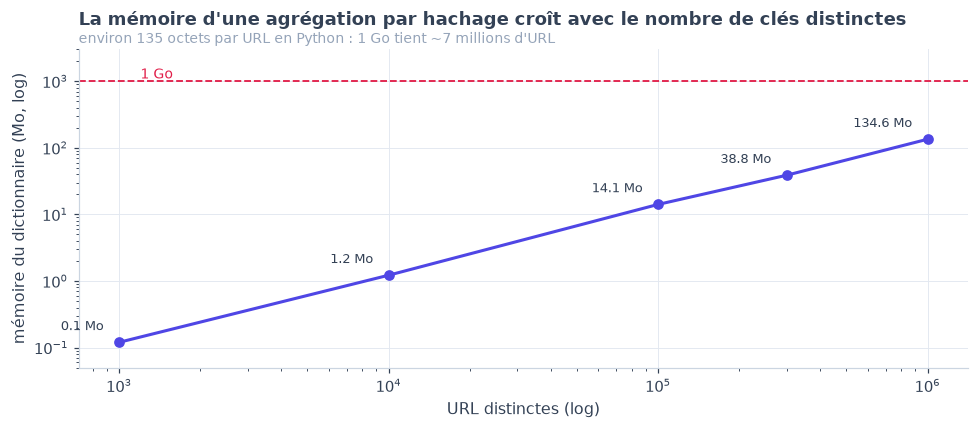

In [11]:
def memoire_dict(n):
    tracemalloc.start()
    dct = {}
    for i in range(n):
        dct[f"/{2010 + i % 13}/{i % 12 + 1:02d}/{i % 28 + 1:02d}/article-{i}.html"] = i
    cur, _ = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return cur


ns = np.array([1_000, 10_000, 100_000, 300_000, 1_000_000])
mem = np.array([memoire_dict(int(n)) for n in ns])
par_cle = mem[-1] / ns[-1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(ns, mem / 1e6, "o-", color=INDIGO)
for n_, m_ in zip(ns, mem):
    ax.annotate(f"{m_ / 1e6:.1f} Mo", (n_, m_ / 1e6), (-10, 8), textcoords="offset points", fontsize=8.5, ha="right")
ax.axhline(1000, color=ROSE, ls="--", lw=1.2)
ax.text(1.2e3, 1100, "1 Go", color=ROSE, fontsize=9)
ax.set_xlabel("URL distinctes (log)"); ax.set_ylabel("mémoire du dictionnaire (Mo, log)")
ax.set_title("La mémoire d'une agrégation par hachage croît avec le nombre de clés distinctes")
subtitle(ax, f"environ {par_cle:.0f} octets par URL en Python : 1 Go tient ~{1e9 / par_cle / 1e6:.0f} millions d'URL")
ax.set_ylim(0.05, 3000)
plt.tight_layout(); plt.show()

Un site petit ou moyen tient sans peine dans 1 Go de table de hachage. Mais si l'on
agrège sur une clé à forte cardinalité (couples (IP, URL), identifiants de session...),
l'ensemble de travail dépasse la mémoire et le script s'effondre (pagination, puis
erreur de mémoire).

**Le tri externe.** Le tri, lui, se fait très bien avec peu de mémoire, grâce à
l'algorithme qu'on a vu pour les SSTables et les arbres LSM (section *SSTables and LSM-Trees*,
chapitre 3) :

1. lire l'entrée par paquets qui tiennent en mémoire, trier chaque paquet et l'écrire sur
   disque comme un **segment trié** (*run*) ;
2. **fusionner** les segments : une fusion à $k$ voies lit $k$ segments en parallèle, en
   séquentiel, et garde seulement la tête de chacun dans un tas.

Avec $N$ éléments, une mémoire de $M$ éléments et une fusion à $k$ voies, on obtient
$\lceil N/M \rceil$ segments et il faut $\lceil \log_k \lceil N/M \rceil \rceil$ passes de
fusion ; chaque passe relit et réécrit tout. Les accès sont **séquentiels**, ce que
disques et SSD font le mieux. `B.external_sort` implémente exactement cela ; voyons le
déroulement sur un petit exemple avant de le mesurer.

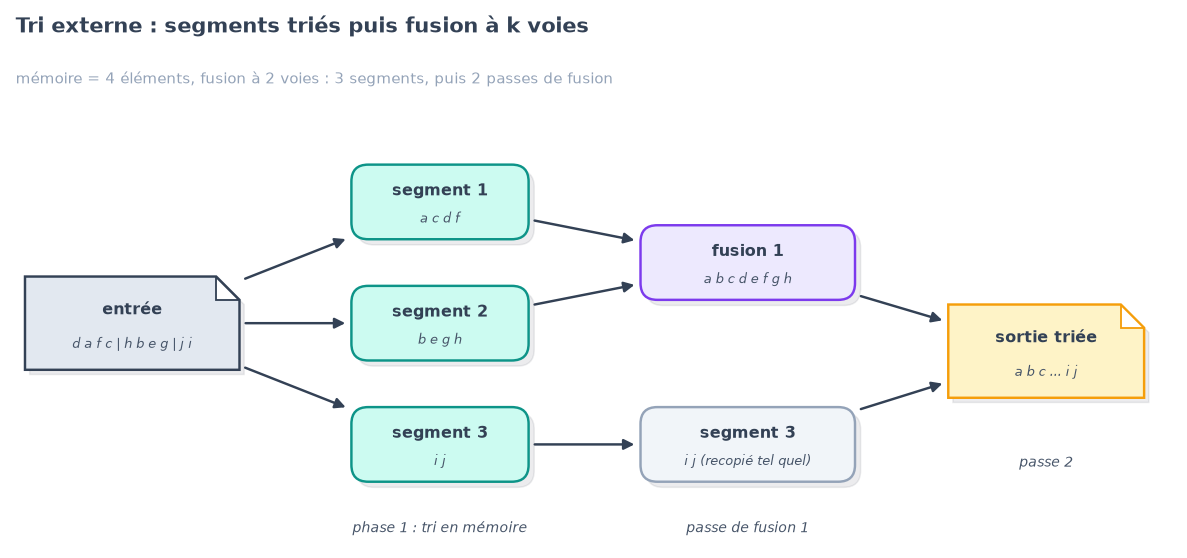

abcdefghij SortStats(n_records=10, n_runs=3, merge_passes=2, max_in_memory=4, records_written=28, records_read=18)


In [12]:
d = Diagram(12.5, 4.8, title="Tri externe : segments triés puis fusion à k voies",
            subtitle="mémoire = 4 éléments, fusion à 2 voies : 3 segments, puis 2 passes de fusion")
d.box("in", 1.3, 2.4, "entrée", sub="d a f c | h b e g | j i", color=SLATE, w=2.3, h=1.0, kind="doc")
d.box("r1", 4.6, 3.7, "segment 1", sub="a c d f", color=TEAL, w=1.9, h=0.8)
d.box("r2", 4.6, 2.4, "segment 2", sub="b e g h", color=TEAL, w=1.9, h=0.8)
d.box("r3", 4.6, 1.1, "segment 3", sub="i j", color=TEAL, w=1.9, h=0.8)
d.box("m1", 7.9, 3.05, "fusion 1", sub="a b c d e f g h", color=VIOLET, w=2.3, h=0.8)
d.box("m2", 7.9, 1.1, "segment 3", sub="i j (recopié tel quel)", color=GRAY, w=2.3, h=0.8)
d.box("out", 11.1, 2.1, "sortie triée", sub="a b c ... i j", color=AMBER, w=2.1, h=1.0, kind="doc")
for r in ("r1", "r2", "r3"):
    d.arrow("in", r, "")
d.arrow("r1", "m1", ""); d.arrow("r2", "m1", ""); d.arrow("r3", "m2", "")
d.arrow("m1", "out", ""); d.arrow("m2", "out", "")
d.note(4.6, 0.2, "phase 1 : tri en mémoire", fontsize=9)
d.note(7.9, 0.2, "passe de fusion 1", fontsize=9)
d.note(11.1, 0.9, "passe 2", fontsize=9)
d.show()
petit, st_petit = B.external_sort(list("dafchbegji"), max_in_memory=4, fan_in=2)
print("".join(petit), st_petit)

Mesurons maintenant le tri externe des 400 000 URL du journal en faisant varier la
mémoire disponible (fusion à 8 voies) : nombre de segments, de passes et d'éléments
écrits sur disque, comparés à la formule.

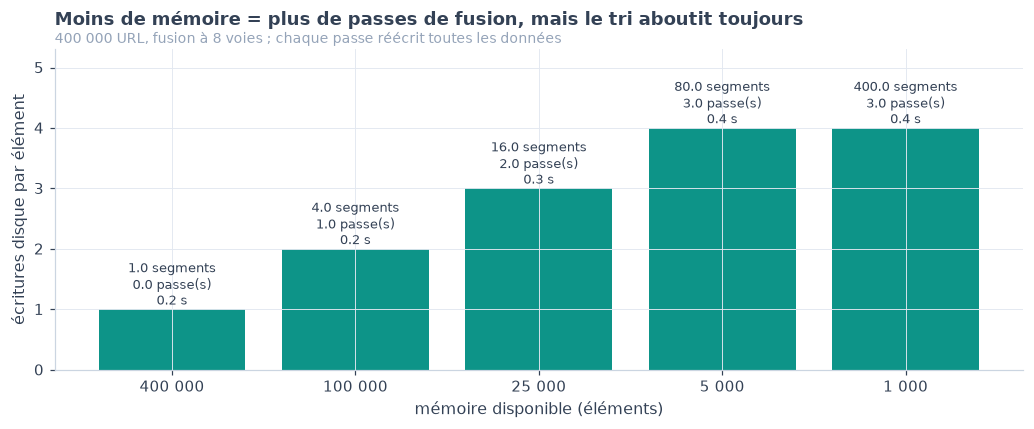

,memoire,segments,passes,passes_formule,ecrits_par_element,duree_s
0,400000,1,0,0,1.0,0.161
1,100000,4,1,1,2.0,0.236
2,25000,16,2,2,3.0,0.319
3,5000,80,3,3,4.0,0.416
4,1000,400,3,3,4.0,0.444


In [13]:
urls = [B.url_of(l) for l in lines]
rows = []
for M_ in [400_000, 100_000, 25_000, 5_000, 1_000]:
    t0 = time.perf_counter()
    trie, st = B.external_sort(urls, max_in_memory=M_, fan_in=8, tmpdir=tempfile.mkdtemp(dir=WORK))
    dt = time.perf_counter() - t0
    assert trie == sorted(urls)
    rows.append(dict(memoire=M_, segments=st.n_runs, passes=st.merge_passes,
                     passes_formule=B.merge_passes(st.n_runs, 8), ecrits_par_element=st.records_written / st.n_records,
                     duree_s=dt))
X = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.bar(range(len(X)), X.ecrits_par_element, color=TEAL)
for i, r in X.iterrows():
    ax.text(i, r.ecrits_par_element + 0.08, f"{r.segments} segments\n{r.passes} passe(s)\n{r.duree_s:.1f} s",
            ha="center", fontsize=8.5)
ax.set_xticks(range(len(X))); ax.set_xticklabels([f"{m:,}".replace(",", " ") for m in X.memoire])
ax.set_xlabel("mémoire disponible (éléments)"); ax.set_ylabel("écritures disque par élément")
ax.set_ylim(0, X.ecrits_par_element.max() + 1.3)
ax.set_title("Moins de mémoire = plus de passes de fusion, mais le tri aboutit toujours")
subtitle(ax, "400 000 URL, fusion à 8 voies ; chaque passe réécrit toutes les données")
plt.tight_layout(); plt.show()
X

Les passes mesurées coïncident avec la formule $\lceil \log_8(\text{segments}) \rceil$.
Diviser la mémoire par 400 fait passer de 1 à 4 écritures par élément (l'écriture des
segments plus trois passes de fusion) : le coût du tri externe croît comme le
**logarithme** du rapport données/mémoire, pas proportionnellement à lui. Les durées
restent ici modestes car les fichiers temporaires tiennent dans le cache de pages du
système ; sur des données plus grosses que la RAM, chaque passe coûterait une lecture et
une écriture complètes du disque.

`sort` de GNU Coreutils fait la même chose : il trie en mémoire jusqu'à la taille fixée
par `-S`, déborde dans des fichiers temporaires, fusionne, et parallélise le tri sur
plusieurs cœurs. Le pipeline Unix passe donc à l'échelle des fichiers plus gros que la
mémoire sans qu'on change une ligne ; le facteur limitant devient la vitesse de lecture
du disque. Vérifions qu'il donne le même résultat avec un tampon minuscule.

In [14]:
rows = []
for opt, lib in [("", "par défaut"), ("-S 64M", "-S 64M"), ("-S 1M", "-S 1M"), ("-S 64K", "-S 64K"),
                 ("-S 64K --parallel=1", "-S 64K, 1 cœur")]:
    ts = []
    for _ in range(3):
        res_, dt = B.unix_top_k(LOG, 5, sort_opts=f"-T {WORK} {opt}")
        ts.append(dt)
    assert res_ == top_unix
    rows.append({"options du premier sort": lib, "durée médiane (s)": np.median(ts)})
pd.DataFrame(rows)

,options du premier sort,durée médiane (s)
0,par défaut,0.126
1,-S 64M,0.129
2,-S 1M,0.127
3,-S 64K,0.165
4,"-S 64K, 1 cœur",0.172


Même résultat dans tous les cas. Avec 64 Kio de tampon, `sort` écrit de nombreux
segments temporaires et les fusionne, pour un surcoût modeste sur ce petit fichier
d'URL (quelques mégaoctets, qui restent dans le cache du système) : les écarts entre
options sont de l'ordre du bruit de mesure. Le point important est ailleurs : `sort` termine quelle que soit la mémoire qu'on lui
laisse, alors qu'une table de hachage privée de mémoire ne terminerait pas.

> **À retenir.** L'agrégation en mémoire est la plus simple tant que l'ensemble de
> travail (une entrée par clé distincte) tient en RAM. Au-delà, le **tri externe**
> (segments triés puis fusion à $k$ voies) traite n'importe quel volume avec une mémoire
> bornée, au prix de $\lceil \log_k(N/M) \rceil$ passes séquentielles. C'est ce
> principe que les frameworks distribués reprennent.

## 5. Les tuyaux et la contre-pression

Un tuyau Unix n'écrit rien sur disque : c'est un petit **tampon** en mémoire (64 Kio
sous Linux). Si le consommateur est plus lent que le producteur, le tampon se remplit et
le noyau **bloque** le producteur jusqu'à ce qu'une place se libère : c'est la
**contre-pression** (*backpressure*). Personne ne déborde, et la mémoire reste bornée ;
le pipeline avance simplement au pas de son étage le plus lent. Le livre retrouve ce
mécanisme dans les moteurs de lots qui passent directement la sortie d'une tâche à la
suivante (section *Materialization of Intermediate State*).

`B.simulate_pipe` simule un producteur et un consommateur reliés par un tampon de $B$
éléments. Le diagramme espace-temps montre les premiers éléments avec $B = 2$ : un
producteur rapide (1 unité par élément) bute sur un consommateur deux fois plus lent.

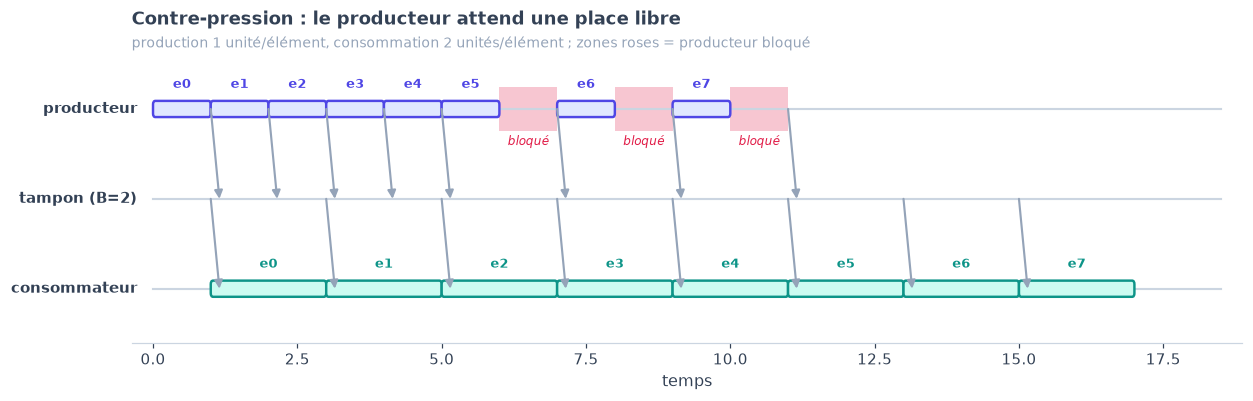

In [15]:
n = 8
r = B.simulate_pipe(np.full(n, 1.0), np.full(n, 2.0), buffer_size=2)
st = SpaceTime(["producteur", "tampon (B=2)", "consommateur"], t_max=18.5, width=11.5,
               title="Contre-pression : le producteur attend une place libre",
               subtitle="production 1 unité/élément, consommation 2 unités/élément ; zones roses = producteur bloqué")
t_prod = 0.0
for i in range(n):
    ready = t_prod + 1.0                       # l'élément i est fabriqué entre t_prod et ready
    st.op("producteur", t_prod, ready, f"e{i}", color=INDIGO)
    if r["put"][i] > ready + 1e-9:             # puis il attend une place dans le tampon
        st.span("producteur", ready, r["put"][i], "bloqué", color=ROSE)
    t_prod = r["put"][i]
    st.msg("producteur", r["put"][i], "tampon (B=2)", r["put"][i] + 0.15, "", color=GRAY)
    st.msg("tampon (B=2)", r["take"][i], "consommateur", r["take"][i] + 0.15, "", color=GRAY)
    st.op("consommateur", r["take"][i], r["done"][i], f"e{i}", color=TEAL)
st.show()

Dès que le tampon est plein (à partir de e5), le producteur passe la moitié de son temps
bloqué : il est ralenti exactement au rythme du consommateur. Sur un flux long, la taille du
tampon ne change pas le débit (imposé par l'étage le plus lent) ; elle sert à absorber
les **à-coups**. Simulons un consommateur dont le temps de traitement varie
(exponentiel), avec différents tampons.

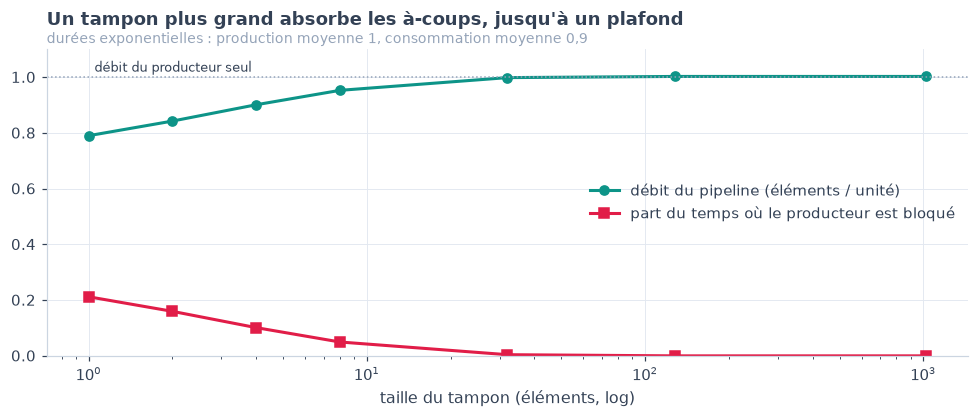

,tampon,debit,bloque
0,1,0.790,0.212
1,2,0.843,0.160
2,4,0.901,0.101
3,8,0.953,0.050
4,32,0.999,0.004
5,128,1.003,0.000
6,1024,1.003,0.000


In [16]:
rng = np.random.default_rng(4)
n = 20_000
prod = rng.exponential(1.0, n)
cons = rng.exponential(0.9, n)                 # en moyenne un peu plus rapide que le producteur
rows = []
for Bsz in [1, 2, 4, 8, 32, 128, 1024]:
    rr = B.simulate_pipe(prod, cons, Bsz)
    rows.append(dict(tampon=Bsz, debit=n / rr["done"][-1], bloque=float(rr["producer_blocked"]) / rr["done"][-1]))
T = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.semilogx(T.tampon, T.debit, "o-", color=TEAL, label="débit du pipeline (éléments / unité)")
ax.semilogx(T.tampon, T.bloque, "s-", color=ROSE, label="part du temps où le producteur est bloqué")
ax.axhline(1.0, color=GRAY, ls=":", lw=1)
ax.text(1.05, 1.02, "débit du producteur seul", fontsize=8.5, color=SLATE)
ax.set_xlabel("taille du tampon (éléments, log)"); ax.set_ylim(0, 1.1)
ax.set_title("Un tampon plus grand absorbe les à-coups, jusqu'à un plafond")
subtitle(ax, "durées exponentielles : production moyenne 1, consommation moyenne 0,9")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()
T.round(3)

Avec un tampon d'un seul élément, les deux processus s'attendent mutuellement et le
débit chute nettement ; quelques dizaines d'éléments suffisent pour retrouver presque le
débit du producteur. Au-delà, un tampon plus grand n'apporte plus rien : il faudrait
accélérer l'étage le plus lent.

> **À retenir.** Un tuyau est un tampon borné : quand il est plein, le producteur est
> bloqué (contre-pression) et le pipeline avance au rythme de son étage le plus lent,
> avec une mémoire constante. La taille du tampon absorbe la variabilité, elle ne crée
> pas de débit.